# SEM defect classification with 28 synthetic Class 1 images

## Archived thesis implementation: +50% configuration

This notebook trains a classification head on a frozen ResNet50V2 backbone. Twenty-eight VAE-generated images are appended to the training subset. The augmentation label refers to 55 original Class 1 images.

This publication copy changes documentation and comments only. Executable statements and stored outputs are preserved. No training or evaluation was rerun during cleanup. Stored outputs are historical, not evidence of a fresh successful run.

## Reading and execution

No execution is required to inspect saved results. Paths refer to the original Google Drive workspace. Training and plotting can overwrite model files and figures. This notebook reads existing synthetic images; it does not regenerate them.

## Methodological scope

The VAE used all original Class 1 images, including those later held out from CNN training. The calibration subset guides model selection before being reused for calibration. The archived quantile omits the finite-sample correction described in the thesis. Interpret results as exploratory historical findings, not an independently validated benchmark or a verification of nominal coverage.

## Final comparison

The final comparison uses manually copied historical metrics from individual experiment outputs. It is not a fresh joint evaluation and does not include repeated runs or uncertainty estimates. Treat configuration differences as descriptive comparisons rather than causal effects of augmentation alone.


## 1. Environment and plotting defaults

Install dependencies and mount Google Drive. Seeds support repeatability but do not guarantee identical results across environments.


In [ ]:
# --- Step 1: Setup and Libraries ---
!pip install mapie "numpy<2.2.0,>=1.26.0" -q

import tensorflow as tf
from tensorflow import keras
from tensorflow.keras import layers
import matplotlib.pyplot as plt
import matplotlib as mpl
import numpy as np
import seaborn as sns
import pandas as pd
import os, shutil, pathlib
from sklearn.model_selection import train_test_split
from sklearn.metrics import classification_report, confusion_matrix, cohen_kappa_score
from sklearn.utils.class_weight import compute_class_weight
from google.colab import drive

drive.mount('/content/drive')

# --- Global Plot Style ---
mpl.rcParams.update({
    'font.family': 'sans-serif',
    'font.size': 11,
    'axes.titlesize': 13,
    'axes.labelsize': 11,
    'axes.spines.top': False,
    'axes.spines.right': False,
    'axes.grid': True,
    'grid.linestyle': ':',
    'grid.alpha': 0.5,
    'lines.linewidth': 1.8,
    'figure.dpi': 150,
})
COLORS = ['#2c7bb6', '#d7191c', '#1a9641', '#fdae61']

print("TensorFlow Version:", tf.__version__)
print("Setup complete.")

# Set random seeds; cross-environment reproducibility is not guaranteed.
import random
SEED = 42
os.environ['PYTHONHASHSEED'] = str(SEED)
random.seed(SEED)
np.random.seed(SEED)
tf.random.set_seed(SEED)
print(f"Global seed set to {SEED} – results are now reproducible.")

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 216.4/216.4 kB 18.9 MB/s eta 0:00:00
Mounted at /content/drive
TensorFlow Version: 2.19.0
Setup complete.
Global seed set to 42 – results are now reproducible.


## 2. Load originals and add 28 synthetic images

Split original images into stratified training, calibration, and test subsets (70/15/15). Append the first 28 alphabetically sorted synthetic JPEG files to training. The +50% label refers to the 55 original Class 1 images, not the training-subset count. The source VAE used all 55 images, including images later held out from CNN training. Original paths are not explicitly sorted before splitting. This cell replaces the local working folder.


In [ ]:
# --- Step 2: Load Data and Add +50% Synthetic Images ---
dataset_path  = pathlib.Path('/content/drive/MyDrive/CarinthiaDataset')
drive_img_dir = dataset_path / 'classified_images'
synth_dir     = dataset_path / 'synthetic_images_class_1'
local_dir     = pathlib.Path('/content/filtered_data')
figures_path  = dataset_path / 'figures'
os.makedirs(figures_path, exist_ok=True)

# Copy originals locally for faster I/O
if local_dir.exists(): shutil.rmtree(local_dir)
local_dir.mkdir()

print("Copying original data...")
for cls in ['class_1', 'class_3', 'class_4']:
    src = drive_img_dir / cls
    if src.exists():
        shutil.copytree(src, local_dir / cls)
        print(f"  -> '{cls}' copied ({len(list((local_dir/cls).glob('*')))} images)")

# Collect paths and labels
all_paths   = [str(p) for p in local_dir.glob('*/*')
               if p.suffix in ['.jpg', '.png', '.jpeg']]
class_names   = sorted([d.name for d in local_dir.iterdir() if d.is_dir()])
class_indices = {name: i for i, name in enumerate(class_names)}
all_labels    = [class_indices[pathlib.Path(p).parent.name] for p in all_paths]

print(f"\nTotal original images: {len(all_paths)}")
print(f"Class mapping: {class_indices}")

# 70/15/15 split on originals ONLY
X_train_orig, X_temp, y_train_orig, y_temp = train_test_split(
    all_paths, all_labels, test_size=0.30, stratify=all_labels, random_state=123)
X_cal, X_test, y_cal, y_test = train_test_split(
    X_temp, y_temp, test_size=0.50, stratify=y_temp, random_state=123)

# Add +50% synthetic images for class_1 (50% of 55 originals = 28 images)
NUM_SYNTH     = 28
synth_files   = sorted(synth_dir.glob('*.jpg'))[:NUM_SYNTH]
synth_paths   = [str(p) for p in synth_files]
label_class_1 = class_indices['class_1']
synth_labels  = [label_class_1] * len(synth_paths)

if len(synth_paths) < NUM_SYNTH:
    print(f"WARNING: Only {len(synth_paths)} synthetic images found (expected {NUM_SYNTH}).")
    NUM_SYNTH = len(synth_paths)

X_train = X_train_orig + synth_paths
y_train = y_train_orig + synth_labels

print(f"\nFinal data split:")
print(f"  Training Set:    {len(X_train)} ({NUM_SYNTH} synthetic)")
print(f"  Calibration Set: {len(X_cal)} (originals only)")
print(f"  Test Set:        {len(X_test)} (originals only)")
print(f"  Class_1 in Cal:  {sum(1 for l in y_cal  if l == label_class_1)}")
print(f"  Class_1 in Test: {sum(1 for l in y_test if l == label_class_1)}")

# Build TF Datasets
IMG_SIZE   = (224, 224)
BATCH_SIZE = 32

def load_image(path, label):
    image = tf.io.read_file(path)
    image = tf.io.decode_jpeg(image, channels=3)
    image = tf.image.resize(image, IMG_SIZE)
    return image, label

train_dataset = (tf.data.Dataset.from_tensor_slices((X_train, y_train))
                 .map(load_image, num_parallel_calls=tf.data.AUTOTUNE)
                 .shuffle(len(X_train)).batch(BATCH_SIZE).prefetch(tf.data.AUTOTUNE))
cal_dataset   = (tf.data.Dataset.from_tensor_slices((X_cal, y_cal))
                 .map(load_image, num_parallel_calls=tf.data.AUTOTUNE)
                 .batch(BATCH_SIZE).cache().prefetch(tf.data.AUTOTUNE))
test_dataset  = (tf.data.Dataset.from_tensor_slices((X_test, y_test))
                 .map(load_image, num_parallel_calls=tf.data.AUTOTUNE)
                 .batch(BATCH_SIZE).cache().prefetch(tf.data.AUTOTUNE))

print("\nDatasets ready.")


Copying original data...
  -> 'class_1' copied (55 images)
  -> 'class_3' copied (4008 images)
  -> 'class_4' copied (289 images)

Total original images: 4352
Class mapping: {'class_1': 0, 'class_3': 1, 'class_4': 2}

Final data split:
  Training Set:    3074 (28 synthetic)
  Calibration Set: 653 (originals only)
  Test Set:        653 (originals only)
  Class_1 in Cal:  8
  Class_1 in Test: 8

Datasets ready.


## 3. Define the classifier

Train a classification head on a frozen ImageNet-pretrained ResNet50V2 backbone, with training-time augmentation. The backbone is not fine-tuned.


In [ ]:
# --- Step 3: Model Architecture (ResNet50V2 + Augmentation) ---
num_classes = len(class_names)

data_augmentation = keras.Sequential([
    layers.RandomFlip("horizontal_and_vertical"),
    layers.RandomRotation(0.3),
    layers.RandomZoom(0.2),
    layers.RandomTranslation(0.1, 0.1),
    layers.RandomContrast(0.2),
    layers.RandomBrightness(0.2),
    layers.GaussianNoise(0.1)
], name="data_augmentation")

base_model = tf.keras.applications.ResNet50V2(
    input_shape=(IMG_SIZE[0], IMG_SIZE[1], 3),
    include_top=False, weights='imagenet')
base_model.trainable = False

inputs  = keras.Input(shape=(IMG_SIZE[0], IMG_SIZE[1], 3))
x       = data_augmentation(inputs)
x       = tf.keras.applications.resnet_v2.preprocess_input(x)
x       = base_model(x, training=False)
x       = layers.GlobalAveragePooling2D()(x)
x       = layers.Dropout(0.3)(x)
outputs = layers.Dense(num_classes, activation='softmax')(x)

model = keras.Model(inputs, outputs, name="Model_50Percent_Synth")
model.compile(
    optimizer=keras.optimizers.Adam(learning_rate=0.001),
    loss=tf.keras.losses.SparseCategoricalCrossentropy(),
    metrics=['accuracy'])

print(f"Model '{model.name}' ready.")
model.summary()


94668760/94668760 ━━━━━━━━━━━━━━━━━━━━ 5s 0us/step
Model 'Model_50Percent_Synth' ready.


Model: "Model_50Percent_Synth"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ input_layer_1 (InputLayer)      │ (None, 224, 224, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ data_augmentation (Sequential)  │ (None, 224, 224, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ true_divide (TrueDivide)        │ (None, 224, 224, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ subtract (Subtract)             │ (None, 224, 224, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ resnet50v2 (Functional)         │ (None, 7, 7, 2048)     │    23,564,800 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ global_average_pooling2d        │ (None, 2048)           │             0 │
│ (GlobalAveragePooling2D)        │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 2048)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 3)              │         6,147 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 23,570,947 (89.92 MB)

 Trainable params: 6,147 (24.01 KB)

 Non-trainable params: 23,564,800 (89.89 MB)

## 4. Compute class weights and train

Compute balanced class weights and train with early stopping, checkpoint selection, and learning-rate reduction. The calibration subset guides model selection and is subsequently reused for conformal calibration. Running this section may overwrite model files.


In [ ]:
# Calibration data also guide model selection in this archived protocol.
# Running this cell may overwrite the original checkpoint.
# --- Step 4: Class Weights and Training ---
weights       = compute_class_weight('balanced', classes=np.unique(y_train), y=y_train)
class_weights = dict(enumerate(weights))
print("Class Weights (higher = more important):")
for name, idx in class_indices.items():
    print(f"  {name}: {class_weights[idx]:.2f}")

checkpoint_path = str(dataset_path / 'models' / 'model_50percent_best.keras')
os.makedirs(os.path.dirname(checkpoint_path), exist_ok=True)

callbacks = [
    tf.keras.callbacks.EarlyStopping(
        monitor='val_loss', patience=10,
        restore_best_weights=True, verbose=1),
    tf.keras.callbacks.ModelCheckpoint(
        checkpoint_path, save_best_only=True,
        monitor='val_loss', verbose=1),
    tf.keras.callbacks.ReduceLROnPlateau(
        monitor='val_loss', factor=0.5,
        patience=5, min_lr=1e-6, verbose=1)
]

print("\nStarting training (+50% Synth)...")
history = model.fit(
    train_dataset,
    validation_data=cal_dataset,
    epochs=100,
    class_weight=class_weights,
    callbacks=callbacks)
print("Training complete. Best model saved to Drive.")


Class Weights (higher = more important):
  class_1: 15.29
  class_3: 0.37
  class_4: 5.07

Starting training (+50% Synth)...
Epoch 1/100
97/97 ━━━━━━━━━━━━━━━━━━━━ 0s 116ms/step - accuracy: 0.8332 - loss: 0.5510
Epoch 1: val_loss improved from None to 0.13734, saving model to /content/drive/MyDrive/CarinthiaDataset/models/model_50percent_best.keras

Epoch 1: finished saving model to /content/drive/MyDrive/CarinthiaDataset/models/model_50percent_best.keras
97/97 ━━━━━━━━━━━━━━━━━━━━ 57s 182ms/step - accuracy: 0.8966 - loss: 0.3297 - val_accuracy: 0.9632 - val_loss: 0.1373 - learning_rate: 0.0010
Epoch 2/100
96/97 ━━━━━━━━━━━━━━━━━━━━ 0s 114ms/step - accuracy: 0.9650 - loss: 0.1177
Epoch 2: val_loss did not improve from 0.13734
97/97 ━━━━━━━━━━━━━━━━━━━━ 19s 135ms/step - accuracy: 0.9678 - loss: 0.1145 - val_accuracy: 0.9648 - val_loss: 0.1384 - learning_rate: 0.0010
Epoch 3/100
96/97 ━━━━━━━━━━━━━━━━━━━━ 0s 117ms/step - accuracy: 0.9683 - loss: 0.1164
Epoch 3: val_loss improved from 0.1

## 5. Inspect learning curves

Display historical training and validation curves. Validation uses the calibration subset, not a separate validation split.


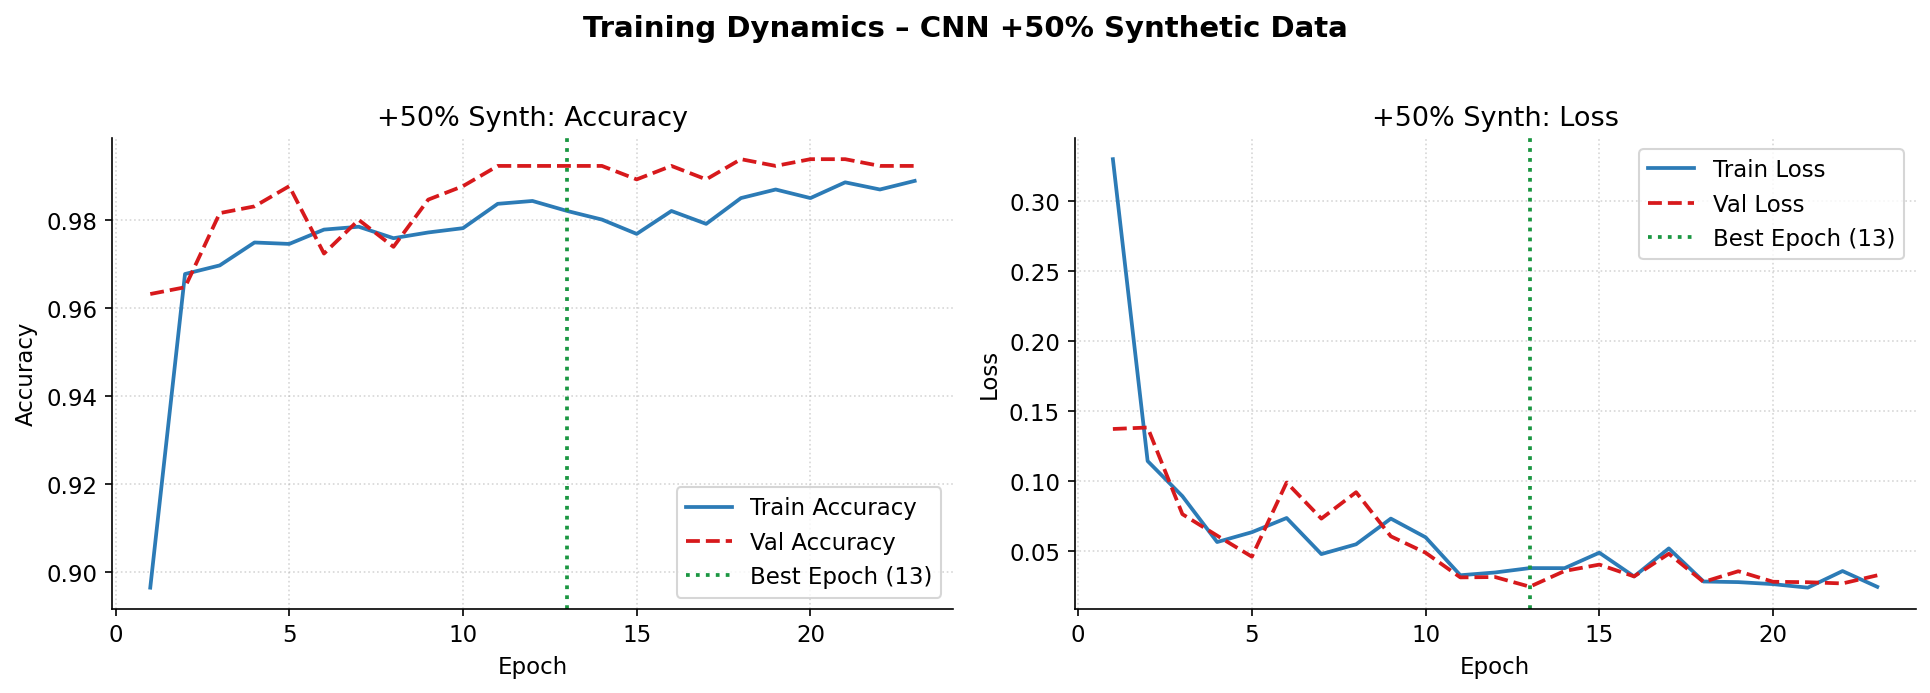

Figure saved: /content/drive/MyDrive/CarinthiaDataset/figures/fig_50pct_learning_curves.png


In [ ]:
# --- Step 5: Learning Curves ---
acc      = history.history['accuracy']
val_acc  = history.history['val_accuracy']
loss     = history.history['loss']
val_loss = history.history['val_loss']
ep_range = range(1, len(acc) + 1)
best_epoch = np.argmin(val_loss) + 1

fig, axes = plt.subplots(1, 2, figsize=(13, 4.5))

axes[0].plot(ep_range, acc,     color=COLORS[0], label='Train Accuracy')
axes[0].plot(ep_range, val_acc, color=COLORS[1], linestyle='--', label='Val Accuracy')
axes[0].axvline(best_epoch, color=COLORS[2], linestyle=':',
                label=f'Best Epoch ({best_epoch})')
axes[0].set_title('+50% Synth: Accuracy')
axes[0].set_xlabel('Epoch')
axes[0].set_ylabel('Accuracy')
axes[0].legend()

axes[1].plot(ep_range, loss,     color=COLORS[0], label='Train Loss')
axes[1].plot(ep_range, val_loss, color=COLORS[1], linestyle='--', label='Val Loss')
axes[1].axvline(best_epoch, color=COLORS[2], linestyle=':',
                label=f'Best Epoch ({best_epoch})')
axes[1].set_title('+50% Synth: Loss')
axes[1].set_xlabel('Epoch')
axes[1].set_ylabel('Loss')
axes[1].legend()

plt.suptitle('Training Dynamics – CNN +50% Synthetic Data',
             fontsize=14, fontweight='bold', y=1.02)
plt.tight_layout()
save_path = str(figures_path / 'fig_50pct_learning_curves.png')
plt.savefig(save_path, bbox_inches='tight')
plt.show()
print(f"Figure saved: {save_path}")


## 6. Check model interfaces and inspect an example

Check output shape and softmax normalization, then display one test example. These checks do not validate generalization, data independence, or coverage.


  SMOKE TEST & SANITY CHECK – CNN +50%

[1/3] Smoke test (dummy input)...
      PASS – Output shape: (1, 3)

[2/3] Softmax sanity check...
      PASS – Probabilities sum to 1.000000

[3/3] Visual check on a real test image...


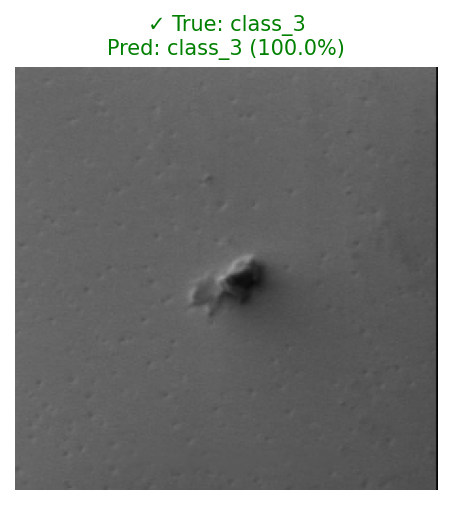


      True: class_3 | Pred: class_3 (100.0%) ✓

  ALL CHECKS PASSED


In [ ]:
# --- Step 6: Smoke Test & Sanity Check ---
import random
print("=" * 55)
print("  SMOKE TEST & SANITY CHECK – CNN +50%")
print("=" * 55)

# 1. Output shape
print("\n[1/3] Smoke test (dummy input)...")
dummy      = np.random.rand(1, 224, 224, 3).astype(np.float32)
pred_dummy = model.predict(dummy, verbose=0)
assert pred_dummy.shape == (1, num_classes), f"Wrong shape: {pred_dummy.shape}"
print(f"      PASS – Output shape: {pred_dummy.shape}")

# 2. Softmax sum
print("\n[2/3] Softmax sanity check...")
prob_sum = np.sum(pred_dummy)
assert 0.99 <= prob_sum <= 1.01
print(f"      PASS – Probabilities sum to {prob_sum:.6f}")

# 3. Visual check on a real test image
print("\n[3/3] Visual check on a real test image...")
idx             = random.randint(0, len(X_test) - 1)
real_path       = X_test[idx]
real_label_name = class_names[y_test[idx]]

img        = keras.utils.load_img(real_path, target_size=(224, 224))
img_arr    = keras.utils.img_to_array(img)
pred_prob  = model.predict(np.expand_dims(img_arr, 0), verbose=0)
pred_name  = class_names[np.argmax(pred_prob)]
confidence = np.max(pred_prob)
correct    = "✓" if pred_name == real_label_name else "✗"

plt.figure(figsize=(3.5, 3.5))
plt.imshow(img.resize((224, 224)))
plt.axis('off')
color = 'green' if pred_name == real_label_name else 'red'
plt.title(f"{correct} True: {real_label_name}\nPred: {pred_name} ({confidence:.1%})",
          color=color, fontsize=10)
plt.tight_layout()
plt.show()

print(f"\n      True: {real_label_name} | Pred: {pred_name} ({confidence:.1%}) {correct}")
print("\n" + "=" * 55)
print("  ALL CHECKS PASSED")
print("=" * 55)


## 7. Evaluate the selected checkpoint

Report class-wise metrics, Cohen's kappa, and a confusion matrix. The source VAE saw original images later assigned to calibration and testing; this limits independence of the evaluation of the complete pipeline. Saved outputs are historical.


Loading best model...

--- Classification Report (+50% Synth) ---
              precision    recall  f1-score   support

     class_1       0.80      1.00      0.89         8
     class_3       1.00      1.00      1.00       602
     class_4       1.00      0.95      0.98        43

    accuracy                           1.00       653
   macro avg       0.93      0.98      0.95       653
weighted avg       1.00      1.00      1.00       653

--- Cohen's Kappa (+50% Synthetic) ---
κ = 0.9685


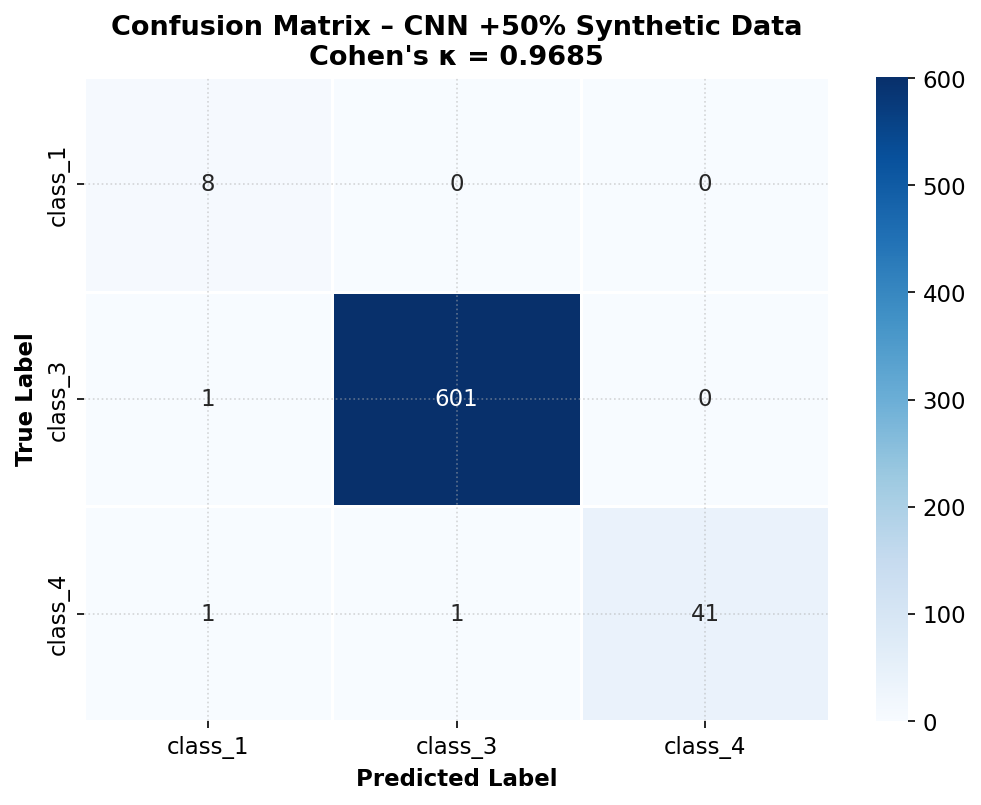

Figure saved: /content/drive/MyDrive/CarinthiaDataset/figures/fig_50pct_confusion_matrix.png


In [ ]:
# --- Step 7: Evaluation on Test Set ---
print("Loading best model...")
best_model = keras.models.load_model(checkpoint_path)

y_true_test  = np.concatenate([y for x, y in test_dataset], axis=0)
y_pred_probs = best_model.predict(test_dataset, verbose=0)
y_pred       = np.argmax(y_pred_probs, axis=1)

print("\n--- Classification Report (+50% Synth) ---")
print(classification_report(y_true_test, y_pred, target_names=class_names))

# Cohen's Kappa
kappa = cohen_kappa_score(y_true_test, y_pred)
print(f"--- Cohen's Kappa (+50% Synthetic) ---")
print(f"κ = {kappa:.4f}")

# Confusion Matrix
cm = confusion_matrix(y_true_test, y_pred)
fig, ax = plt.subplots(figsize=(7, 5.5))
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues',
            xticklabels=class_names, yticklabels=class_names,
            linewidths=0.5, ax=ax)
ax.set_ylabel('True Label', fontweight='bold')
ax.set_xlabel('Predicted Label', fontweight='bold')
ax.set_title(f'Confusion Matrix – CNN +50% Synthetic Data\nCohen\'s κ = {kappa:.4f}',
             fontweight='bold')
plt.tight_layout()
save_path = str(figures_path / 'fig_50pct_confusion_matrix.png')
plt.savefig(save_path, bbox_inches='tight')
plt.show()
print(f"Figure saved: {save_path}")


## 8. Construct and evaluate prediction sets

Compute scores as one minus the true-class probability. The archived code uses NumPy's default interpolated 99th percentile, without the finite-sample correction described in the thesis. The calibration subset also guided model selection. Empirical coverage at a nominal 99% target does not establish the standard finite-sample coverage guarantee.


In [ ]:
# Historical implementation: interpolated quantile without finite-sample correction.
# Construct prediction sets using the archived percentile-based calibration.
print("--- Conformal Prediction (+50% Experiment) ---")

X_cal_pool  = np.concatenate([x for x, y in cal_dataset],  axis=0)
y_cal_pool  = np.concatenate([y for x, y in cal_dataset],  axis=0)
X_test_pool = np.concatenate([x for x, y in test_dataset], axis=0)
y_test_pool = np.concatenate([y for x, y in test_dataset], axis=0)

y_probs_cal  = best_model.predict(X_cal_pool,  verbose=0)
y_probs_test = best_model.predict(X_test_pool, verbose=0)

# Non-conformity scores: 1 - P(true class)
scores_cal = 1 - y_probs_cal[np.arange(len(y_cal_pool)), y_cal_pool]

alpha          = 0.01
q_hat          = np.quantile(scores_cal, 1 - alpha)
threshold      = 1 - q_hat
prediction_sets = [np.where(p >= threshold)[0] for p in y_probs_test]

coverage     = np.mean([y_test_pool[i] in prediction_sets[i]
                        for i in range(len(y_test_pool))])
avg_set_size = np.mean([len(s) for s in prediction_sets])

print(f"\n--- CP Results (+50% Synth, alpha={alpha}) ---")
print(f"  q_hat (99% confidence):   {q_hat:.4f}")
print(f"  Empirical Coverage:       {coverage:.2%}  (target: ≥{(1-alpha):.0%})")
print(f"  Avg. Prediction Set Size: {avg_set_size:.3f}")

results_50percent = {
    "model": "+50% Synth",
    "coverage": coverage,
    "avg_set_size": avg_set_size,
    "q_hat": q_hat,
}


--- Conformal Prediction (+50% Experiment) ---

--- CP Results (+50% Synth, alpha=0.01) ---
  q_hat (99% confidence):   0.2690
  Empirical Coverage:       99.23%  (target: ≥99%)
  Avg. Prediction Set Size: 0.995


## 9. Plot the calibration threshold

Display sorted calibration scores and their threshold. Original references to 99% confidence are not per-image correctness guarantees. At inference, candidate labels have scores; the true-label score is unavailable without ground truth.


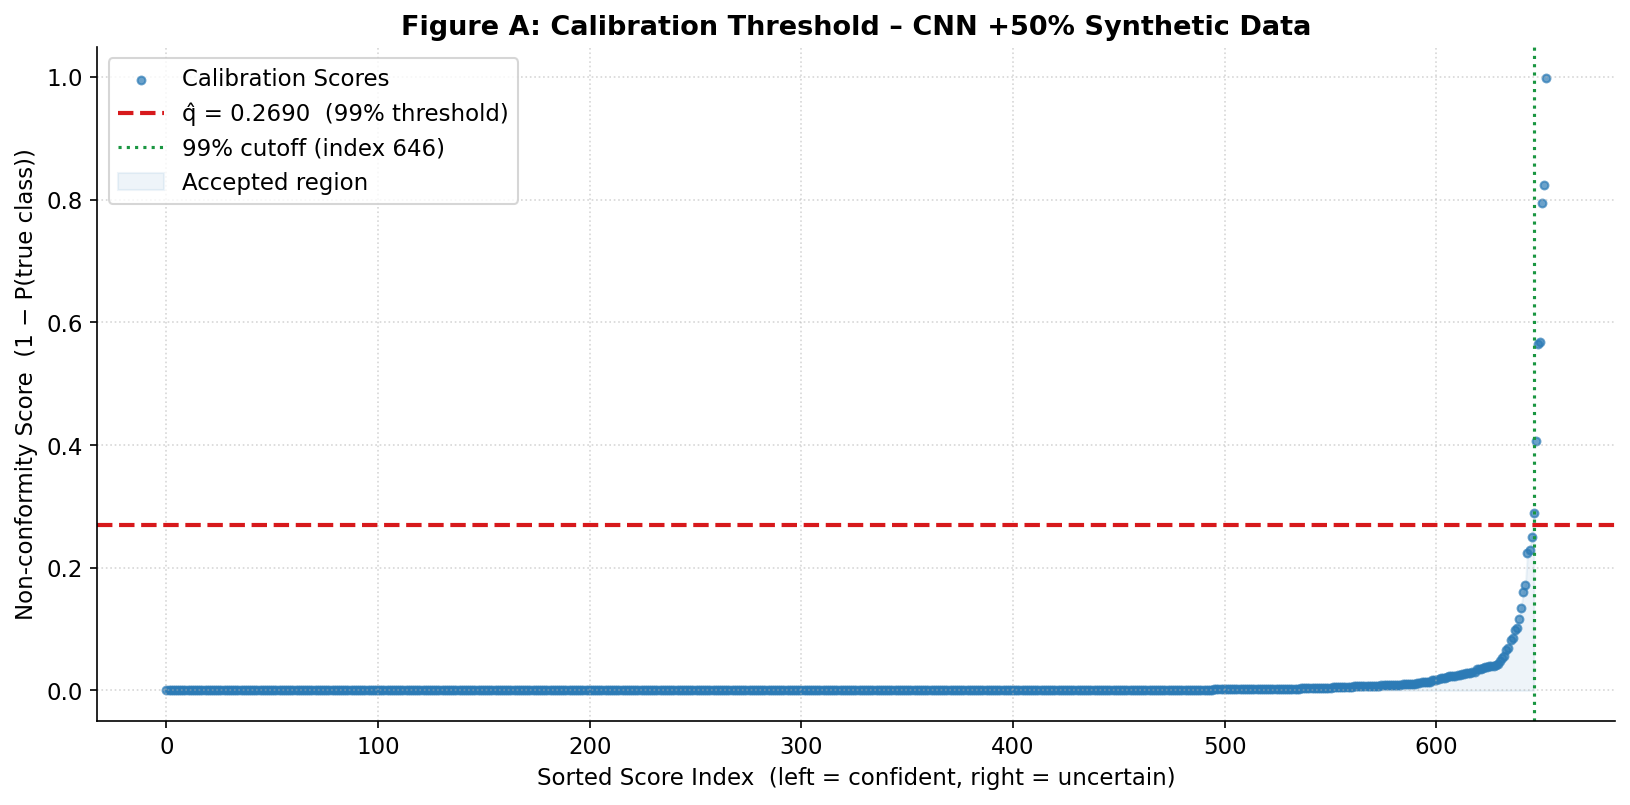

Figure saved: /content/drive/MyDrive/CarinthiaDataset/figures/fig_50pct_calibration_threshold.png
Interpretation: All images with score ≤ 0.2690 accepted at 99% confidence.


In [ ]:
# --- Step 9: Calibration Threshold Plot (Figure A) ---
sorted_scores = np.sort(scores_cal)
score_idx     = np.arange(len(sorted_scores))
cutoff_idx    = int(len(sorted_scores) * (1 - alpha))

fig, ax = plt.subplots(figsize=(11, 5.5))
ax.scatter(score_idx, sorted_scores, s=14, color=COLORS[0], alpha=0.7,
           label='Calibration Scores')
ax.axhline(q_hat, color=COLORS[1], linestyle='--', linewidth=2,
           label=f'q̂ = {q_hat:.4f}  (99% threshold)')
ax.axvline(cutoff_idx, color=COLORS[2], linestyle=':', linewidth=1.5,
           label=f'99% cutoff (index {cutoff_idx})')
ax.fill_between(score_idx, 0, sorted_scores,
                where=(score_idx <= cutoff_idx),
                color=COLORS[0], alpha=0.08, label='Accepted region')
ax.set_title('Figure A: Calibration Threshold – CNN +50% Synthetic Data',
             fontweight='bold')
ax.set_xlabel('Sorted Score Index  (left = confident, right = uncertain)')
ax.set_ylabel('Non-conformity Score  (1 − P(true class))')
ax.legend()
plt.tight_layout()
save_path = str(figures_path / 'fig_50pct_calibration_threshold.png')
plt.savefig(save_path, bbox_inches='tight')
plt.show()
print(f"Figure saved: {save_path}")
print(f"Interpretation: All images with score ≤ {q_hat:.4f} accepted at 99% confidence.")


## 10. Inspect class-wise coverage and set size

Report descriptive class-wise coverage and prediction-set sizes, not class-conditional guarantees. The saved test report has eight Class 1 examples. Sets can be empty; mean set size must be interpreted together with coverage.


--- Per-Class CP Analysis (+50% Synth) ---

  class_1 (n=   8):  Coverage=87.50%  |  Avg Set Size=0.875
  class_3 (n= 602):  Coverage=99.67%  |  Avg Set Size=0.997
  class_4 (n=  43):  Coverage=95.35%  |  Avg Set Size=1.000


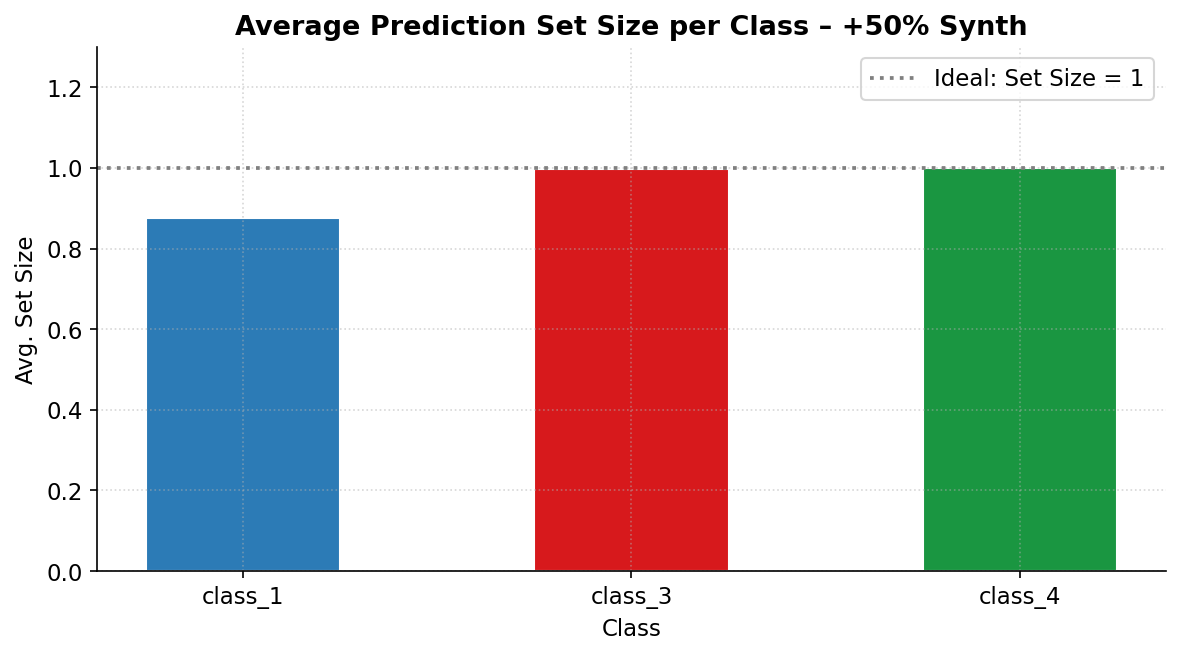

Figure saved: /content/drive/MyDrive/CarinthiaDataset/figures/fig_50pct_setsize_per_class.png


In [ ]:
# --- Step 10: Per-Class Conformal Prediction Analysis ---
print("--- Per-Class CP Analysis (+50% Synth) ---\n")

for class_idx, class_name in enumerate(class_names):
    mask         = y_test_pool == class_idx
    sets_for_cls = [prediction_sets[i] for i in range(len(y_test_pool)) if mask[i]]
    true_labels  = y_test_pool[mask]
    if len(true_labels) == 0:
        continue
    cov = np.mean([true_labels[i] in sets_for_cls[i] for i in range(len(true_labels))])
    avg = np.mean([len(s) for s in sets_for_cls])
    print(f"  {class_name} (n={len(true_labels):4d}):  "
          f"Coverage={cov:.2%}  |  Avg Set Size={avg:.3f}")

# Bar chart: avg set size per class
sizes_by_class = {name: [] for name in class_names}
for i, s in enumerate(prediction_sets):
    sizes_by_class[class_names[y_test_pool[i]]].append(len(s))

fig, ax = plt.subplots(figsize=(8, 4.5))
ax.bar(class_names,
       [np.mean(sizes_by_class[c]) for c in class_names],
       color=COLORS[:len(class_names)], width=0.5, edgecolor='white')
ax.axhline(1.0, color='gray', linestyle=':', label='Ideal: Set Size = 1')
ax.set_title('Average Prediction Set Size per Class – +50% Synth', fontweight='bold')
ax.set_ylabel('Avg. Set Size')
ax.set_xlabel('Class')
ax.set_ylim(0, max([np.mean(sizes_by_class[c]) for c in class_names]) + 0.3)
ax.legend()
plt.tight_layout()
save_path = str(figures_path / 'fig_50pct_setsize_per_class.png')
plt.savefig(save_path, bbox_inches='tight')
plt.show()
print(f"Figure saved: {save_path}")


## 11. Compare archived experiment summaries

Display manually copied summary metrics from the baseline and synthetic-image configurations. These values are historical, manually transferred results—not a fresh joint evaluation. The configurations differ in synthetic-image counts and training runs; differences should not be attributed solely to augmentation. The comparison does not include uncertainty estimates or repeated training runs.


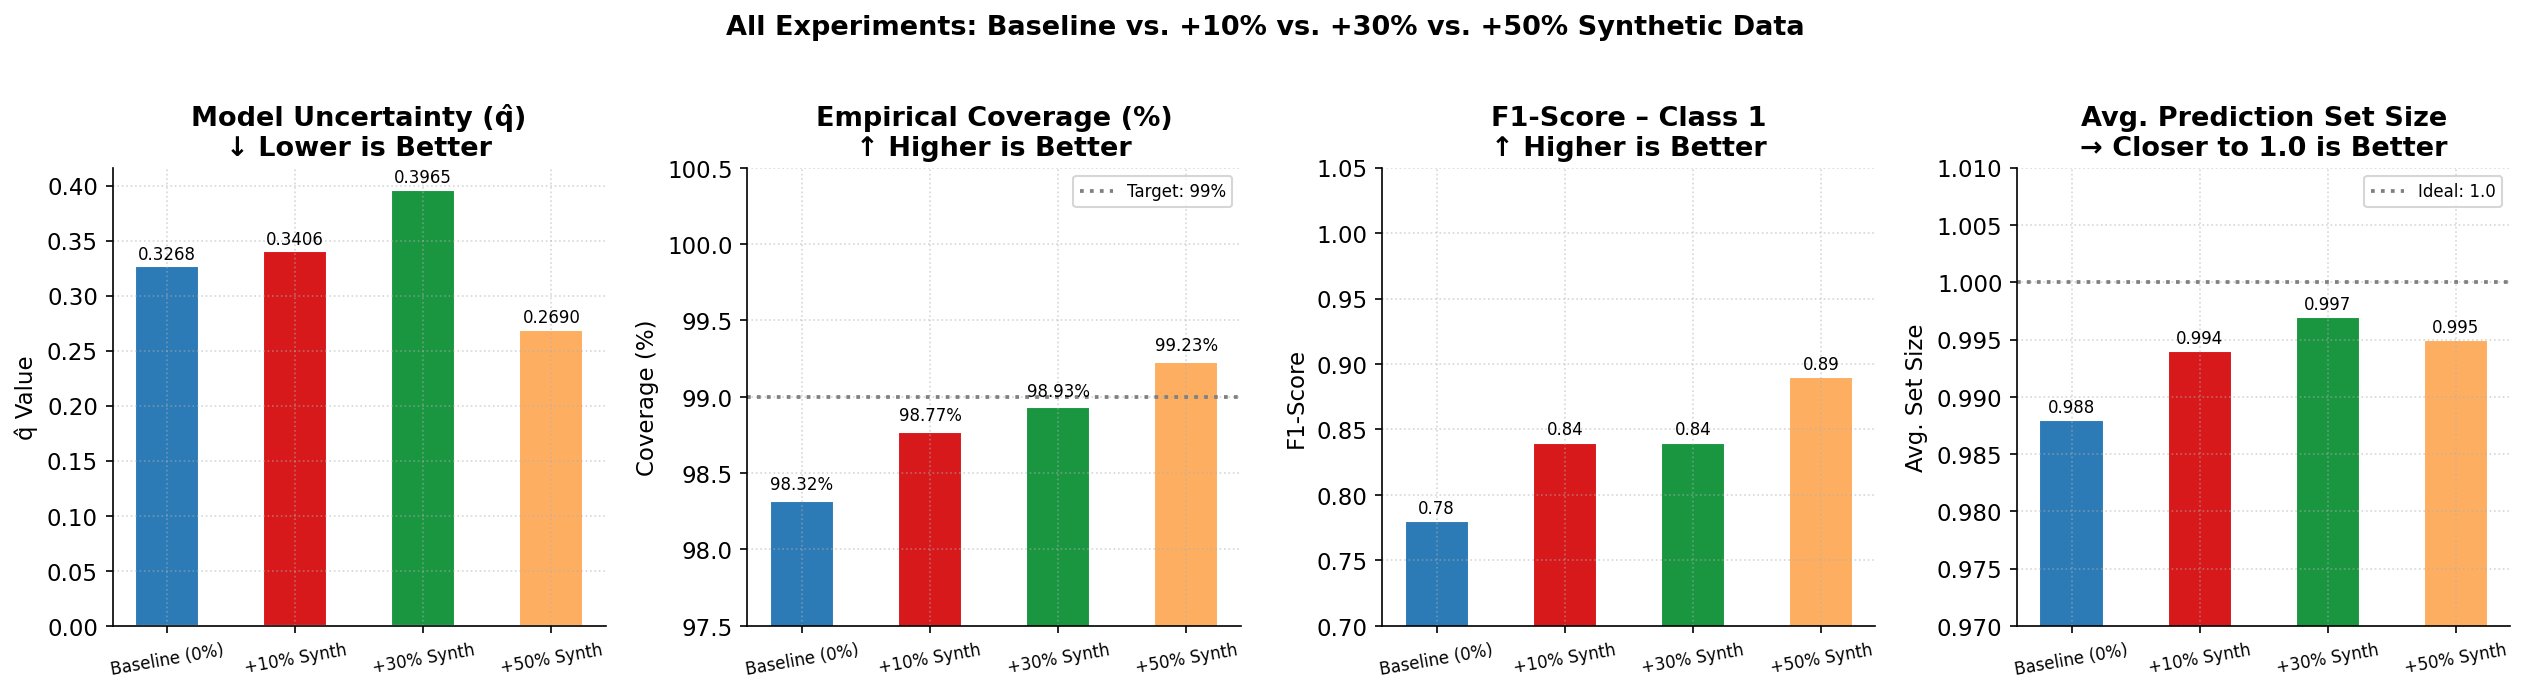

Figure saved: /content/drive/MyDrive/CarinthiaDataset/figures/fig_comparison_all_experiments.png


In [ ]:
# --- Step 11: Final Comparison – All Experiments ---

# Manually copied historical summary values; not a fresh joint evaluation.
results_baseline  = {"model": "Baseline (0%)", "coverage": 0.9832,
                     "avg_set_size": 0.988, "q_hat": 0.3268, "class1_f1": 0.78}
results_10percent = {"model": "+10% Synth",    "coverage": 0.9877,
                     "avg_set_size": 0.994, "q_hat": 0.3406, "class1_f1": 0.84}
results_30percent = {"model": "+30% Synth",    "coverage": 0.9893,
                     "avg_set_size": 0.997, "q_hat": 0.3965, "class1_f1": 0.84}
results_50percent = {"model": "+50% Synth",    "coverage": 0.9923,
                     "avg_set_size": 0.995, "q_hat": 0.2690, "class1_f1": 0.89}

all_results = [results_baseline, results_10percent,
               results_30percent, results_50percent]
models     = [r["model"]         for r in all_results]
q_hats     = [r["q_hat"]         for r in all_results]
coverages  = [r["coverage"]*100  for r in all_results]
f1_class1  = [r["class1_f1"]     for r in all_results]
set_sizes  = [r["avg_set_size"]  for r in all_results]


fig, axes = plt.subplots(1, 4, figsize=(17, 4.5))
x      = np.arange(len(models))
bar_kw = dict(width=0.5, edgecolor='white')

# Plot 1: q_hat
bars = axes[0].bar(x, q_hats, color=COLORS, **bar_kw)
axes[0].set_title('Model Uncertainty (q̂)\n↓ Lower is Better', fontweight='bold')
axes[0].set_ylabel('q̂ Value')
axes[0].set_xticks(x); axes[0].set_xticklabels(models, fontsize=8, rotation=10)
for bar, val in zip(bars, q_hats):
    axes[0].text(bar.get_x() + bar.get_width()/2, bar.get_height() + 0.003,
                 f'{val:.4f}', ha='center', va='bottom', fontsize=8)

# Plot 2: Coverage
bars = axes[1].bar(x, coverages, color=COLORS, **bar_kw)
axes[1].axhline(99.0, color='gray', linestyle=':', label='Target: 99%')
axes[1].set_title('Empirical Coverage (%)\n↑ Higher is Better', fontweight='bold')
axes[1].set_ylabel('Coverage (%)')
axes[1].set_ylim(97.5, 100.5)
axes[1].set_xticks(x); axes[1].set_xticklabels(models, fontsize=8, rotation=10)
axes[1].legend(fontsize=8)
for bar, val in zip(bars, coverages):
    axes[1].text(bar.get_x() + bar.get_width()/2, bar.get_height() + 0.05,
                 f'{val:.2f}%', ha='center', va='bottom', fontsize=8)

# Plot 3: F1 Class 1
bars = axes[2].bar(x, f1_class1, color=COLORS, **bar_kw)
axes[2].set_title('F1-Score – Class 1\n↑ Higher is Better', fontweight='bold')
axes[2].set_ylabel('F1-Score')
axes[2].set_ylim(0.70, 1.05)
axes[2].set_xticks(x); axes[2].set_xticklabels(models, fontsize=8, rotation=10)
for bar, val in zip(bars, f1_class1):
    axes[2].text(bar.get_x() + bar.get_width()/2, bar.get_height() + 0.003,
                 f'{val:.2f}', ha='center', va='bottom', fontsize=8)

# Plot 4: Avg Set Size
bars = axes[3].bar(x, set_sizes, color=COLORS, **bar_kw)
axes[3].axhline(1.0, color='gray', linestyle=':', label='Ideal: 1.0')
axes[3].set_title('Avg. Prediction Set Size\n→ Closer to 1.0 is Better', fontweight='bold')
axes[3].set_ylabel('Avg. Set Size')
axes[3].set_ylim(0.97, 1.01)
axes[3].set_xticks(x); axes[3].set_xticklabels(models, fontsize=8, rotation=10)
axes[3].legend(fontsize=8)
for bar, val in zip(bars, set_sizes):
    axes[3].text(bar.get_x() + bar.get_width()/2, bar.get_height() + 0.0003,
                 f'{val:.3f}', ha='center', va='bottom', fontsize=8)

plt.suptitle('All Experiments: Baseline vs. +10% vs. +30% vs. +50% Synthetic Data',
             fontsize=13, fontweight='bold', y=1.02)
plt.tight_layout()
save_path = str(figures_path / 'fig_comparison_all_experiments.png')
plt.savefig(save_path, bbox_inches='tight')
plt.show()
print(f"Figure saved: {save_path}")
